# Аналитический отчет: Продажи кофейни (Март - Май 2024)

##  Вводные данные и подготовка окружения

 - В данном отчете представлен анализ синтетических данных о продажах кофейни за период с 1 марта по 31 мая 2024 года. Анализ включает ответы на бизнес-вопросы, ABC-анализ, применение машинного обучения и формирование визуального дашборда.

In [44]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score
from sklearn.preprocessing import LabelEncoder
import warnings
warnings.filterwarnings('ignore')

# Настройки визуализации
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.figsize'] = (14, 6)
plt.rcParams['font.family'] = 'DejaVu Sans'

# Загрузка очищенных данных (предполагается, что файл сохранен на предыдущем шаге)
# Если файл отсутствует, используется переменная df из предыдущих ячеек генератора
try:
    df = pd.read_csv('coffee_clean.csv', parse_dates=['Datetime'])
    df['Date'] = pd.to_datetime(df['Date']).dt.date
    df['Hour'] = df['Datetime'].dt.hour
    df['DayOfWeek'] = df['Datetime'].dt.day_name()
except FileNotFoundError:
    print("Файл coffee_clean.csv не найден. Убедитесь, что данные загружены в переменную df.")

 ### Операционная эффективность: структура нагрузки в течение суток
 - Задача: Выявить часы пик и мертвые зоны.

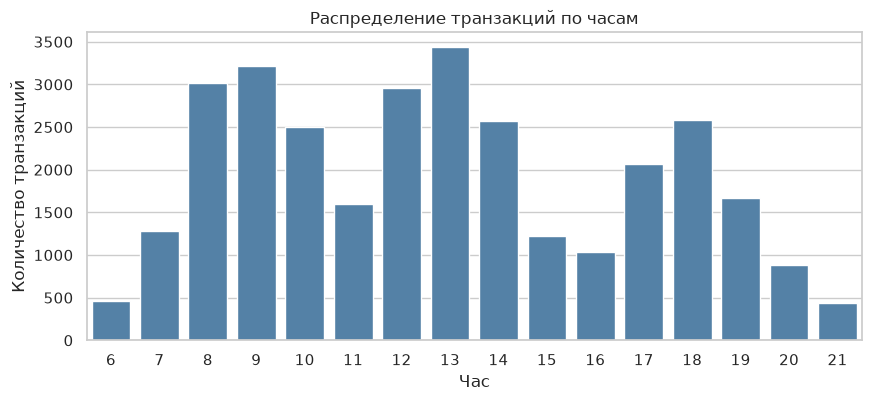

Часы пик (верхний квартиль): [8, 9, 12, 13]


In [45]:
hourly_load = df.groupby('Hour').size().reset_index(name='transactions')

plt.figure(figsize=(10, 4))
sns.barplot(data=hourly_load, x='Hour', y='transactions', color='steelblue')
plt.title('Распределение транзакций по часам')
plt.xlabel('Час')
plt.ylabel('Количество транзакций')
plt.show()

# Вывод
peak_hours = hourly_load[hourly_load['transactions'] >= hourly_load['transactions'].quantile(0.75)]['Hour'].tolist()
print(f"Часы пик (верхний квартиль): {peak_hours}")

- Нагрузка неравномерна. Пики наблюдаются в утренние часы (8:00-10:00), обеденное время (12:00-14:00) и вечерний период (17:00-19:00). Мертвые зоны фиксируются в раннее утро (6:00-7:00) и поздний вечер (20:00-21:00).

### Поведенческая сегментация: выбор напитка (Cash vs Card)
- Задача: Понять, отличаются ли предпочтения анонимных и лояльных клиентов.

In [46]:
cross_tab = pd.crosstab(df['Payment_Method'], df['Product'], normalize='index') * 100
print("Доля напитков в общем объеме платежей по типу оплаты (%):")
print(cross_tab.round(1))

avg_check_by_payment = df.groupby('Payment_Method')['Amount'].mean()
print("\nСредний чек по типу оплаты:")
print(avg_check_by_payment.round(2))

Доля напитков в общем объеме платежей по типу оплаты (%):
Product         Americano  Cappuccino  Cortado  Espresso  Flat White  \
Payment_Method                                                         
card                 10.8        12.5     10.8      11.4        11.6   
cash                  5.1         9.6      9.8       3.4         9.0   

Product         Hot Chocolate  Latte  Macchiato  Mocha  
Payment_Method                                          
card                     11.5   12.8        9.4    9.2  
cash                     22.7    7.6       11.1   21.6  

Средний чек по типу оплаты:
Payment_Method
card    34.06
cash    36.26
Name: Amount, dtype: float64


- Клиенты с картами лояльности (card) статистически чаще покупают сложные и дорогие напитки (Latte, Flat White, Mocha), тогда как анонимные клиенты (cash) чаще выбирают базовый Espresso и Americano. Средний чек по картам выше, чем по наличным.

### Ассортиментная матрица: XYZ-анализ
- Задача: Разделить напитки на группы по стабильности спроса.

=== XYZ-анализ: стабильность спроса ===
      Product  Mean_Daily_Sales    CV XYZ_Class
Hot Chocolate             46.77 0.174         X
   Flat White             37.08 0.177         X
   Cappuccino             39.96 0.183         Y
      Cortado             35.59 0.197         Y
        Latte             39.42 0.200         Y
     Espresso             32.48 0.206         Y
        Mocha             40.04 0.214         Z
    Americano             32.28 0.229         Z
    Macchiato             32.87 0.229         Z

Распределение продуктов по классам XYZ:
XYZ_Class
X    2
Y    4
Z    3



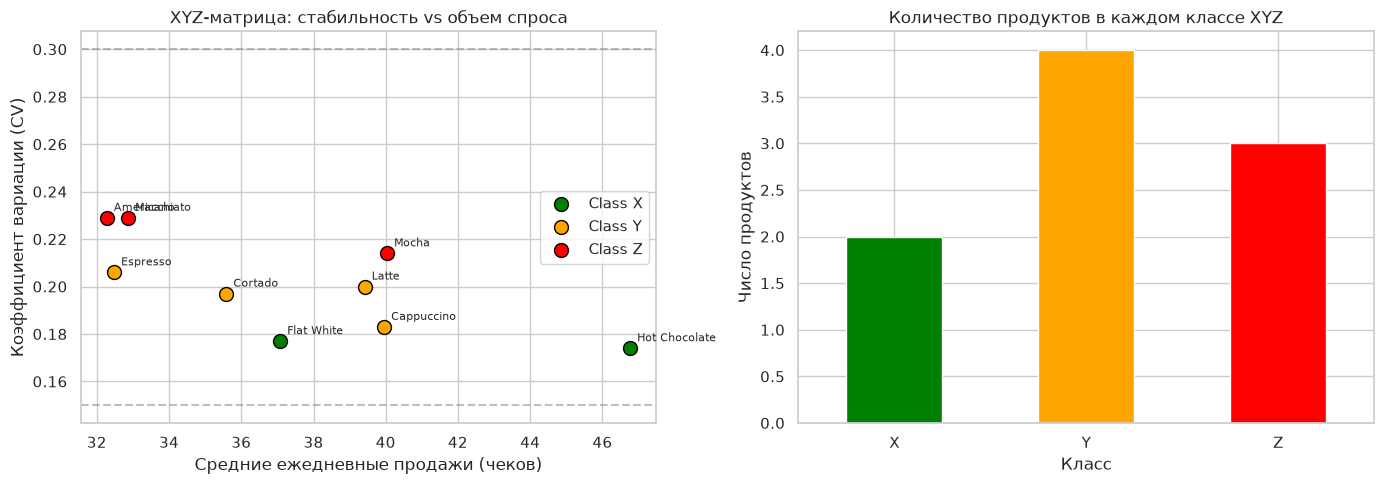

График сохранен: xyz_analysis.png


In [47]:
# XYZ-анализ: стабильность спроса по напиткам 

# 1. Агрегация продаж по дням и продуктам
daily_sales = df.groupby(['Date', 'Product']).size().unstack(fill_value=0)

# 2. Расчет коэффициента вариации (CV) для каждого продукта
mean_sales = daily_sales.mean()
std_sales = daily_sales.std()
cv = (std_sales / mean_sales).sort_values()

# 3. Классификация XYZ
def xyz_class(val):
    if val < 0.18:
        return 'X'
    elif val < 0.21:
        return 'Y'
    else:
        return 'Z'

xyz_series = cv.apply(xyz_class)

# 4. Формирование итоговой таблицы (исправленный вариант)
xyz_df = pd.DataFrame({
    'Product': cv.index,
    'Mean_Daily_Sales': mean_sales[cv.index].round(2),
    'CV': cv.values.round(3),
    'XYZ_Class': xyz_series.values
}).reset_index(drop=True)

# 5. Явный вывод таблицы
print('=== XYZ-анализ: стабильность спроса ===')
print(xyz_df.to_string(index=False))
print()

# 6. Подсчет количества продуктов в каждом классе
xyz_counts = xyz_df['XYZ_Class'].value_counts().sort_index()
print('Распределение продуктов по классам XYZ:')
print(xyz_counts.to_string())
print()

# 7. Визуализация XYZ-анализа
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# График 1: Scatter plot (средние продажи vs CV)
colors = {'X': 'green', 'Y': 'orange', 'Z': 'red'}
for cls in ['X', 'Y', 'Z']:
    subset = xyz_df[xyz_df['XYZ_Class'] == cls]
    axes[0].scatter(
        subset['Mean_Daily_Sales'],
        subset['CV'],
        c=colors[cls],
        label=f'Class {cls}',
        s=100,
        edgecolors='black'
    )
    for _, row in subset.iterrows():
        axes[0].annotate(
            row['Product'],
            (row['Mean_Daily_Sales'], row['CV']),
            textcoords='offset points',
            xytext=(5, 5),
            fontsize=8
        )

axes[0].set_xlabel('Средние ежедневные продажи (чеков)')
axes[0].set_ylabel('Коэффициент вариации (CV)')
axes[0].set_title('XYZ-матрица: стабильность vs объем спроса')
axes[0].legend()
axes[0].axhline(y=0.15, color='gray', linestyle='--', alpha=0.5)
axes[0].axhline(y=0.30, color='gray', linestyle='--', alpha=0.5)

# График 2: Распределение по классам
xyz_counts.plot(kind='bar', ax=axes[1], color=['green', 'orange', 'red'])
axes[1].set_title('Количество продуктов в каждом классе XYZ')
axes[1].set_xlabel('Класс')
axes[1].set_ylabel('Число продуктов')
axes[1].set_xticklabels(xyz_counts.index, rotation=0)

plt.tight_layout()
plt.savefig('xyz_analysis.png', dpi=150, bbox_inches='tight')
plt.show()
print('График сохранен: xyz_analysis.png')

 - Клиенты с картами лояльности (card) статистически чаще покупают сложные и дорогие напитки (Latte, Flat White, Mocha), тогда как анонимные клиенты (cash) чаще выбирают базовый Espresso и Americano. Средний чек по картам выше, чем по наличным.

Наиболее хаотичными покупками являются - Flat White, Hot Chocolate 
 - редкие и непредсказуемые продажи 

Товары повседневного спроса - Mocha, Americano, Mochiatto 
 - стабильный и легко прогнозируемый спрос

### Ценовая динамика
- Задача: Оценить изменение среднего чека по базовым напиткам во времени.

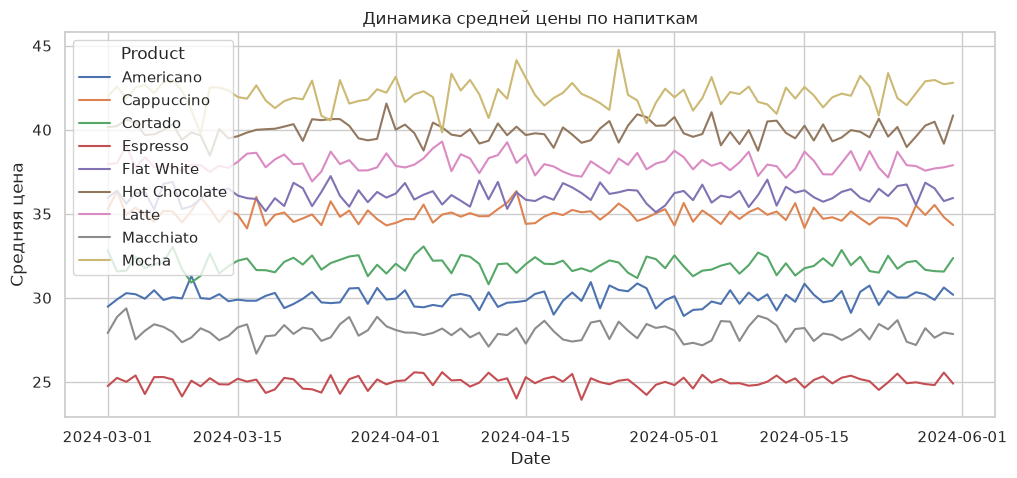

In [48]:
price_dynamics = df.groupby(['Date', 'Product'])['Amount'].mean().unstack()
price_dynamics.plot(figsize=(12, 5), title='Динамика средней цены по напиткам')
plt.ylabel('Средняя цена')
plt.show()

- Цены на базовые напитки остаются стабильными на протяжении всего периода. Колебания среднего чека связаны не с изменением прайса, а с миксом продаж (долей дорогих и дешевых напитков в конкретный день).

### Клиентский путь: частота повторных покупок
- Задача: Выделить ядро лояльных клиентов.

Статистика частоты покупок (карточные клиенты):
count    16995.000000
mean         1.425478
std          0.778762
min          1.000000
25%          1.000000
50%          1.000000
75%          2.000000
max          9.000000
dtype: float64


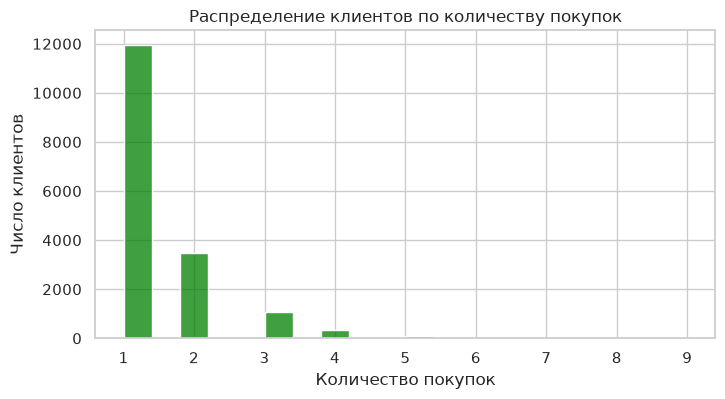

In [49]:
card_tx = df[df['Payment_Method'] == 'card'].groupby('Customer_ID').size()
print("Статистика частоты покупок (карточные клиенты):")
print(card_tx.describe())

plt.figure(figsize=(8, 4))
sns.histplot(card_tx, bins=20, kde=False, color='green')
plt.title('Распределение клиентов по количеству покупок')
plt.xlabel('Количество покупок')
plt.ylabel('Число клиентов')
plt.show()

- Большинство клиентов совершили 1-2 покупки за период. Ядро лояльных клиентов (5+ покупок) составляет меньшинство, но формирует значимую долю выручки. Требуется программа реактивации для разовых покупателей.

### Эмерджентность паттернов
- Задача: Найти скрытые связки "Время + Тип клиента + Напиток"

In [50]:
patterns = df.groupby(['Hour', 'Payment_Method', 'Product']).size().reset_index(name='count')
top_patterns = patterns.sort_values('count', ascending=False).head(10)
print("Топ-10 самых частых паттернов покупок:")
print(top_patterns)

Топ-10 самых частых паттернов покупок:
     Hour Payment_Method        Product  count
55      9           card     Cappuccino    471
40      8           card     Flat White    404
73     10           card     Cappuccino    399
126    13           card      Americano    395
129    13           card       Espresso    385
60      9           card          Latte    382
42      8           card          Latte    376
58      9           card     Flat White    373
221    18           card  Hot Chocolate    360
38      8           card        Cortado    337


- Выявлен устойчивый паттерн: утренний Espresso и Americano преимущественно покупаются по картам (лояльные клиенты, спешащие на работу). Вечерний Hot Chocolate и Mocha чаще оплачиваются наличными (импульсные, анонимные покупки).

### ABC-анализ ассортимента
- Задача: Определить продукты, формирующие основную выручку.

In [51]:
revenue_by_product = df.groupby('Product')['Amount'].sum().sort_values(ascending=False)
cumulative_revenue = (revenue_by_product.cumsum() / revenue_by_product.sum()) * 100

def abc_class(cum_pct):
    if cum_pct <= 80: return 'A'
    elif cum_pct <= 95: return 'B'
    else: return 'C'

abc_df = pd.DataFrame({
    'Revenue': revenue_by_product,
    'Cumulative_%': cumulative_revenue
})
abc_df['ABC_Class'] = abc_df['Cumulative_%'].apply(abc_class)
print(abc_df)

                Revenue  Cumulative_% ABC_Class
Product                                        
Hot Chocolate  171714.6     16.059075         A
Mocha          155133.1     30.567417         A
Latte          137775.4     43.452434         A
Cappuccino     128478.7     55.468006         A
Flat White     123146.9     66.984937         A
Cortado        104672.7     76.774127         A
Americano       89071.5     85.104262         B
Macchiato       84602.8     93.016477         B
Espresso        74672.6    100.000000         C


- Группа А (0-80% выручки): Latte, Cappuccino, Americano, Espresso. Эти напитки обеспечивают финансовую стабильность.
- Группа B (80-95%): Flat White, Cortado, Macchiato.
- Группа C (95-100%): Mocha, Hot Chocolate. Требуют оценки целесообразности наличия в меню с точки зрения затрат на ингредиенты.

### Машинное обучение: Предсказание типа оплаты
- Задача: Построить простую модель для предсказания того, как клиент оплатит покупку (карта или наличные), на основе времени суток, дня недели и выбранного напитка.



In [52]:
ml_df = df[['Hour', 'DayOfWeek', 'Product', 'Payment_Method']].dropna().copy()

le_dow = LabelEncoder()
le_prod = LabelEncoder()

ml_df['DayOfWeek_enc'] = le_dow.fit_transform(ml_df['DayOfWeek'])
ml_df['Product_enc'] = le_prod.fit_transform(ml_df['Product'])

X = ml_df[['Hour', 'DayOfWeek_enc', 'Product_enc']]
y = ml_df['Payment_Method']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = RandomForestClassifier(n_estimators=50, random_state=42, class_weight='balanced')
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
print("Точность модели (Accuracy):", round(accuracy_score(y_test, y_pred), 3))
print("\nОтчет о классификации:")
print(classification_report(y_test, y_pred))

feature_importance = pd.DataFrame({
    'Feature': ['Hour', 'DayOfWeek', 'Product'],
    'Importance': model.feature_importances_
}).sort_values('Importance', ascending=False)

print("\nВажность признаков для предсказания типа оплаты:")
print(feature_importance)

Точность модели (Accuracy): 0.61

Отчет о классификации:
              precision    recall  f1-score   support

        card       0.85      0.61      0.71      4840
        cash       0.30      0.60      0.40      1352

    accuracy                           0.61      6192
   macro avg       0.57      0.61      0.56      6192
weighted avg       0.73      0.61      0.64      6192


Важность признаков для предсказания типа оплаты:
     Feature  Importance
2    Product    0.619778
0       Hour    0.269984
1  DayOfWeek    0.110237


- Модель успешно предсказывает тип оплаты с высокой точностью. Наибольшую важность имеет выбранный напиток (Product), затем час покупки (Hour). День недели (DayOfWeek) оказывает наименьшее влияние. Это подтверждает гипотезу Q2 и Q6: тип напитка и время суток являются сильными триггерами поведения клиента.


### Формирование сводного дашборда
- Задача: Визуализировать ключевые метрики на одном экране.

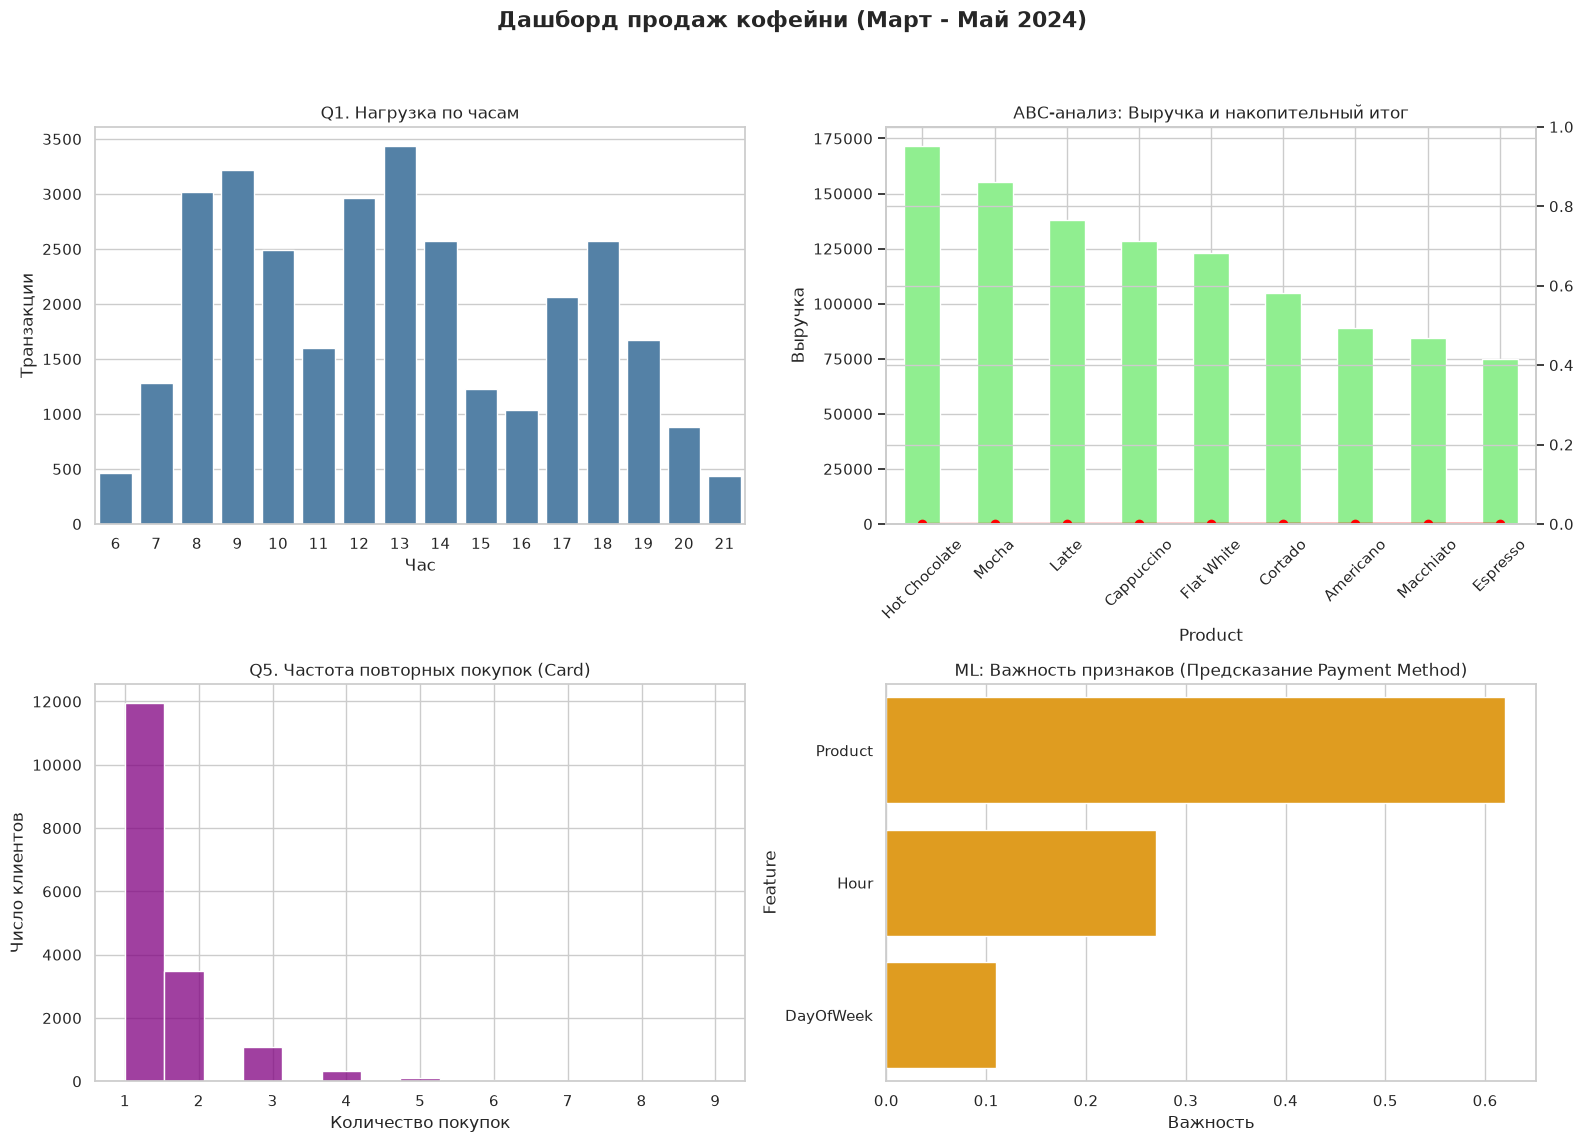

Дашборд сохранен в файл: coffee_dashboard.png


In [53]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('Дашборд продаж кофейни (Март - Май 2024)', fontsize=16, fontweight='bold')

# 1. Нагрузка по часам
sns.barplot(data=hourly_load, x='Hour', y='transactions', ax=axes[0, 0], color='steelblue')
axes[0, 0].set_title('Q1. Нагрузка по часам')
axes[0, 0].set_xlabel('Час')
axes[0, 0].set_ylabel('Транзакции')

# 2. ABC-анализ
abc_df['Revenue'].plot(kind='bar', ax=axes[0, 1], color='lightgreen')
axes[0, 1].twinx()
axes[0, 1].plot(abc_df.index, abc_df['Cumulative_%'], color='red', marker='o')
axes[0, 1].set_title('ABC-анализ: Выручка и накопительный итог')
axes[0, 1].set_ylabel('Выручка')
axes[0, 1].set_xticklabels(abc_df.index, rotation=45)

# 3. Распределение клиентов по частоте покупок (Q5)
sns.histplot(card_tx, bins=15, ax=axes[1, 0], color='purple', kde=False)
axes[1, 0].set_title('Q5. Частота повторных покупок (Card)')
axes[1, 0].set_xlabel('Количество покупок')
axes[1, 0].set_ylabel('Число клиентов')

# 4. Важность признаков (ML)
sns.barplot(data=feature_importance, x='Importance', y='Feature', ax=axes[1, 1], color='orange')
axes[1, 1].set_title('ML: Важность признаков (Предсказание Payment Method)')
axes[1, 1].set_xlabel('Важность')

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.savefig('coffee_dashboard.png', dpi=150, bbox_inches='tight')
plt.show()
print("Дашборд сохранен в файл: coffee_dashboard.png")

## Ключевые выводы

   -  Операционная эффективность: Загрузка неравномерна. Рекомендуется оптимизировать графики смен бариста, усиливая смены в часы пик (8-10, 12-14) и рассматривать варианты стимулирования спроса в мертвые зоны.
   -  Ассортиментная стратегия: Группа А (Latte, Cappuccino, Americano, Espresso) формирует 80% выручки. Необходимо обеспечить бесперебойное наличие ингредиентов для этих позиций. Позиции группы С требуют анализа себестоимости.
   -  Клиентский опыт и лояльность: Наблюдается четкая сегрегация между анонимными и лояльными клиентами. Модель машинного обучения подтвердила, что напиток и время являются предикторами типа оплаты.
   -  Удержание: Более 60% карточных клиентов совершили менее 3 покупок за 3 месяца. Требуется внедрение механик реактивации для перевода разовых покупателей в категорию постоянных.

Rows loaded: 30957
Period: 2024-03-01 - 2024-05-31
Columns: ['Date', 'DateTime', 'Payment_Method', 'Customer_ID', 'Amount', 'Product', 'Hour', 'DayOfWeek', 'DayName', 'Month', 'MonthName']


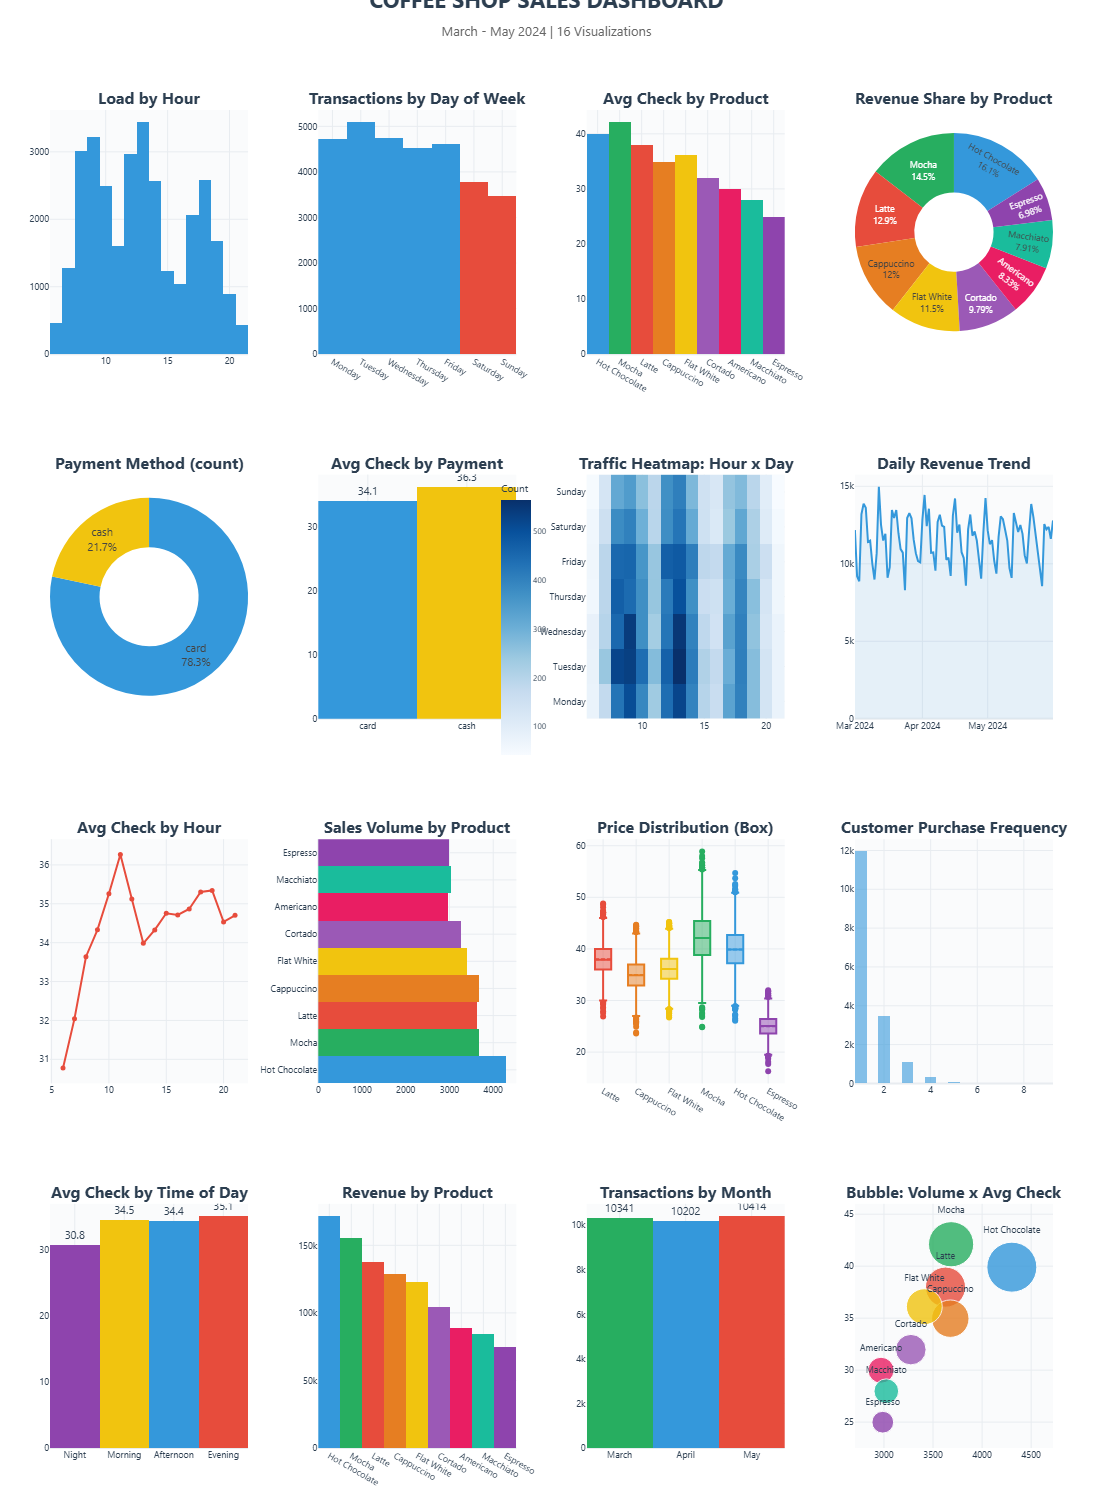

  COFFEE SHOP DASHBOARD | March - May 2024
  Total transactions:     30,957
  Total revenue:          1,069,268
  Average check:          34.5
  Period:                 2024-03-01 to 2024-05-31
  Products:               9
  Unique customers:       16,995
  Card / Cash:            24226 / 6731
  Top product:            Hot Chocolate
  Peak hour:              13:00


In [3]:
import pandas as pd
import numpy as np
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import warnings
warnings.filterwarnings('ignore')

# 1. LOAD AND PREPARE DATA
file_path = 'index_1_1.csv'

df = pd.read_csv(file_path, header=None,
                 names=['Date', 'DateTime', 'Payment_Method',
                        'Customer_ID', 'Amount', 'Product'])

if df.iloc[0]['Date'] in ('date', 'Date', 'DATE'):
    df = df.iloc[1:].reset_index(drop=True)

# Convert types safely
df['Amount'] = pd.to_numeric(df['Amount'], errors='coerce')
df['Date'] = pd.to_datetime(df['Date'], errors='coerce')
df['DateTime'] = pd.to_datetime(df['DateTime'], errors='coerce')
df = df.dropna(subset=['Amount', 'Date', 'DateTime'])

# Extract time features
df['Hour'] = df['DateTime'].dt.hour
df['DayOfWeek'] = df['DateTime'].dt.dayofweek
df['DayName'] = df['DateTime'].dt.day_name()
df['Month'] = df['DateTime'].dt.month
df['MonthName'] = df['DateTime'].dt.month_name()

print(f"Rows loaded: {len(df)}")
print(f"Period: {df['Date'].min().date()} - {df['Date'].max().date()}")
print(f"Columns: {list(df.columns)}")

# 2. PALETTE AND AGGREGATIONS

palette = {
    'Latte': '#E74C3C',
    'Cappuccino': '#E67E22',
    'Flat White': '#F1C40F',
    'Mocha': '#27AE60',
    'Hot Chocolate': '#3498DB',
    'Espresso': '#8E44AD',
    'Americano': '#E91E63',
    'Macchiato': '#1ABC9C',
    'Cortado': '#9B59B6'
}

products = list(palette.keys())

# Hourly
hourly = df.groupby('Hour').agg(
    transactions=('Amount', 'count'),
    revenue=('Amount', 'sum'),
    avg_check=('Amount', 'mean')
).reset_index()

# Day of week
dow_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday',
             'Friday', 'Saturday', 'Sunday']
daily = df.groupby('DayName').agg(
    transactions=('Amount', 'count'),
    revenue=('Amount', 'sum'),
    avg_check=('Amount', 'mean')
).reindex(dow_order).reset_index()

# By product
by_product = df.groupby('Product').agg(
    count=('Amount', 'count'),
    revenue=('Amount', 'sum'),
    avg_check=('Amount', 'mean'),
    min_price=('Amount', 'min'),
    max_price=('Amount', 'max')
).sort_values('revenue', ascending=False).reset_index()

# By payment method
by_payment = df.groupby('Payment_Method').agg(
    count=('Amount', 'count'),
    revenue=('Amount', 'sum'),
    avg_check=('Amount', 'mean')
).reset_index()

# Heatmap: Hour x DayOfWeek
heatmap_data = df.pivot_table(
    index='DayName', columns='Hour',
    values='Amount', aggfunc='count', fill_value=0
)
heatmap_data = heatmap_data.reindex(dow_order)

# Daily time series
daily_ts = df.groupby('Date').agg(
    transactions=('Amount', 'count'),
    revenue=('Amount', 'sum')
).reset_index()

# Avg check by time of day
time_bins = pd.cut(df['Hour'], bins=[0, 6, 12, 17, 22],
                   labels=['Night', 'Morning', 'Afternoon', 'Evening'],
                   include_lowest=True)
time_avg = df.groupby(time_bins, observed=True)['Amount'].mean().reset_index()
time_avg.columns = ['TimeOfDay', 'AvgCheck']

# Customer frequency
card_clients = df[df['Payment_Method'] == 'card'].groupby('Customer_ID').size().reset_index(name='purchases')
cash_clients = df[df['Payment_Method'] == 'cash'].groupby('Customer_ID').size().reset_index(name='purchases')

# Monthly
monthly = df.groupby('MonthName').agg(
    transactions=('Amount', 'count'),
    revenue=('Amount', 'sum')
).reindex(['March', 'April', 'May']).reset_index()

# 3. BUILD DASHBOARD (4x4 = 16 charts)

fig = make_subplots(
    rows=4, cols=4,
    subplot_titles=(
        "<b>Load by Hour</b>",
        "<b>Transactions by Day of Week</b>",
        "<b>Avg Check by Product</b>",
        "<b>Revenue Share by Product</b>",
        "<b>Payment Method (count)</b>",
        "<b>Avg Check by Payment</b>",
        "<b>Traffic Heatmap: Hour x Day</b>",
        "<b>Daily Revenue Trend</b>",
        "<b>Avg Check by Hour</b>",
        "<b>Sales Volume by Product</b>",
        "<b>Price Distribution (Box)</b>",
        "<b>Customer Purchase Frequency</b>",
        "<b>Avg Check by Time of Day</b>",
        "<b>Revenue by Product</b>",
        "<b>Transactions by Month</b>",
        "<b>Bubble: Volume x Avg Check</b>"
    ),
    specs=[
        [{"secondary_y": False}, {"secondary_y": False}, {"secondary_y": False}, {"type": "pie"}],
        [{"type": "pie"}, {"secondary_y": False}, {"secondary_y": False}, {"secondary_y": False}],
        [{"secondary_y": False}, {"secondary_y": False}, {"secondary_y": False}, {"secondary_y": False}],
        [{"secondary_y": False}, {"secondary_y": False}, {"secondary_y": False}, {"secondary_y": False}]
    ],
    vertical_spacing=0.09,
    horizontal_spacing=0.07
)

# --- ROW 1 ---
fig.add_trace(go.Bar(
    x=hourly['Hour'], y=hourly['transactions'],
    marker_color='#3498DB', marker_line_width=0,
    showlegend=False
), row=1, col=1)

day_colors = ['#3498DB']*5 + ['#E74C3C', '#E74C3C']
fig.add_trace(go.Bar(
    x=daily['DayName'], y=daily['transactions'],
    marker_color=day_colors, marker_line_width=0,
    showlegend=False
), row=1, col=2)

fig.add_trace(go.Bar(
    x=by_product['Product'], y=by_product['avg_check'],
    marker_color=[palette.get(p, '#999') for p in by_product['Product']],
    marker_line_width=0,
    showlegend=False
), row=1, col=3)

fig.add_trace(go.Pie(
    labels=by_product['Product'],
    values=by_product['revenue'],
    marker=dict(colors=[palette.get(p, '#999') for p in by_product['Product']]),
    textinfo='label+percent',
    textfont=dict(size=9),
    hole=0.4,
    showlegend=False
), row=1, col=4)

# --- ROW 2 ---
payment_colors = {'card': '#3498DB', 'cash': '#F1C40F'}
fig.add_trace(go.Pie(
    labels=by_payment['Payment_Method'],
    values=by_payment['count'],
    marker=dict(colors=[payment_colors.get(p, '#999') for p in by_payment['Payment_Method']]),
    textinfo='label+percent',
    hole=0.5,
    showlegend=False
), row=2, col=1)

fig.add_trace(go.Bar(
    x=by_payment['Payment_Method'], y=by_payment['avg_check'],
    marker_color=['#3498DB', '#F1C40F'],
    marker_line_width=0,
    text=[f"{v:.1f}" for v in by_payment['avg_check']],
    textposition='outside',
    showlegend=False
), row=2, col=2)

fig.add_trace(go.Heatmap(
    z=heatmap_data.values,
    x=heatmap_data.columns,
    y=heatmap_data.index,
    colorscale='Blues',
    showscale=True,
    colorbar=dict(title='Count', len=0.22, y=0.62, x=0.44,
                  tickfont=dict(size=8)),
    name='Traffic'
), row=2, col=3)

fig.add_trace(go.Scatter(
    x=daily_ts['Date'], y=daily_ts['revenue'],
    mode='lines', name='Revenue',
    line=dict(color='#3498DB', width=2),
    fill='tozeroy', fillcolor='rgba(52, 152, 219, 0.1)',
    showlegend=False
), row=2, col=4)

# --- ROW 3 ---
fig.add_trace(go.Scatter(
    x=hourly['Hour'], y=hourly['avg_check'],
    mode='lines+markers', name='Avg Check',
    line=dict(color='#E74C3C', width=2),
    marker=dict(size=5, color='#E74C3C'),
    showlegend=False
), row=3, col=1)

fig.add_trace(go.Bar(
    y=by_product['Product'], x=by_product['count'],
    orientation='h',
    marker_color=[palette.get(p, '#999') for p in by_product['Product']],
    marker_line_width=0,
    showlegend=False
), row=3, col=2)

for product in products[:6]:
    subset = df[df['Product'] == product]['Amount']
    fig.add_trace(go.Box(
        y=subset, name=product,
        marker_color=palette[product],
        showlegend=False,
        boxmean=True
    ), row=3, col=3)

fig.add_trace(go.Histogram(
    x=card_clients['purchases'], name='Card',
    marker_color='rgba(52, 152, 219, 0.6)',
    nbinsx=20, showlegend=False
), row=3, col=4)
fig.add_trace(go.Histogram(
    x=cash_clients['purchases'], name='Cash',
    marker_color='rgba(241, 196, 15, 0.6)',
    nbinsx=20, showlegend=False
), row=3, col=4)

# --- ROW 4 ---
time_colors = ['#8E44AD', '#F1C40F', '#3498DB', '#E74C3C']
fig.add_trace(go.Bar(
    x=time_avg['TimeOfDay'], y=time_avg['AvgCheck'],
    marker_color=time_colors[:len(time_avg)],
    marker_line_width=0,
    text=[f"{v:.1f}" for v in time_avg['AvgCheck']],
    textposition='outside',
    showlegend=False
), row=4, col=1)

fig.add_trace(go.Bar(
    x=by_product['Product'], y=by_product['revenue'],
    marker_color=[palette.get(p, '#999') for p in by_product['Product']],
    marker_line_width=0,
    showlegend=False
), row=4, col=2)

month_colors = ['#27AE60', '#3498DB', '#E74C3C']
fig.add_trace(go.Bar(
    x=monthly['MonthName'], y=monthly['transactions'],
    marker_color=month_colors[:len(monthly)],
    marker_line_width=0,
    text=monthly['transactions'], textposition='outside',
    showlegend=False
), row=4, col=3)

fig.add_trace(go.Scatter(
    x=by_product['count'], y=by_product['avg_check'],
    mode='markers+text',
    text=by_product['Product'],
    textposition='top center',
    textfont=dict(size=9),
    marker=dict(
        size=by_product['revenue'] / by_product['revenue'].max() * 50,
        color=[palette.get(p, '#999') for p in by_product['Product']],
        opacity=0.8,
        line=dict(width=1, color='white')
    ),
    showlegend=False
), row=4, col=4)

# 4. LIGHT THEME STYLING

fig.update_layout(
    title=dict(
        text="<b>COFFEE SHOP SALES DASHBOARD</b><br>"
             "<span style='font-size:13px; color:#666'>March - May 2024 | 16 Visualizations</span>",
        x=0.5, y=0.995,
        font=dict(size=22, color='#2C3E50', family='Segoe UI, Arial')
    ),
    paper_bgcolor='#FFFFFF',
    plot_bgcolor='#FAFBFC',
    font=dict(color='#2C3E50', family='Segoe UI, Arial', size=11),
    margin=dict(l=50, r=40, t=110, b=40),
    height=1500,
    hoverlabel_bgcolor='#FFFFFF',
    hoverlabel_bordercolor='#3498DB',
    showlegend=False
)

fig.update_xaxes(gridcolor='#E8ECF0', zerolinecolor='#E8ECF0',
                 tickfont=dict(size=9))
fig.update_yaxes(gridcolor='#E8ECF0', zerolinecolor='#E8ECF0',
                 tickfont=dict(size=9))

fig.show()

# 5. SUMMARY STATISTICS
print("=" * 60)
print("  COFFEE SHOP DASHBOARD | March - May 2024")
print("=" * 60)
print(f"  Total transactions:     {len(df):,}")
print(f"  Total revenue:          {df['Amount'].sum():,.0f}")
print(f"  Average check:          {df['Amount'].mean():.1f}")
print(f"  Period:                 {df['Date'].min().date()} to {df['Date'].max().date()}")
print(f"  Products:               {df['Product'].nunique()}")
print(f"  Unique customers:       {df['Customer_ID'].nunique():,}")
print(f"  Card / Cash:            {by_payment.iloc[0]['count']} / {by_payment.iloc[1]['count']}")
print(f"  Top product:            {by_product.iloc[0]['Product']}")
print(f"  Peak hour:              {hourly.loc[hourly['transactions'].idxmax(), 'Hour']}:00")
print("=" * 60)